In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [2]:
from src.backend import is_cuda_available, core_factory

device = "cuda" if is_cuda_available() else "cpu"

device

'cuda'

In [3]:
core = core_factory(device)

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [4]:
train = pd.read_csv("train.csv")
print(f"Train shape: {train.shape}")
train.head()

Train shape: (630000, 13)


,id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,0,21,female,b.sc,7.91,98.8,no,4.9,average,online videos,low,easy,78.3
1,1,18,other,diploma,4.95,94.8,yes,4.7,poor,self-study,medium,moderate,46.7
2,2,20,female,b.sc,4.68,92.6,yes,5.8,poor,coaching,high,moderate,99.0
3,3,19,male,b.sc,2.00,49.5,yes,8.3,average,group study,high,moderate,63.9
4,4,23,male,bca,7.65,86.9,yes,9.6,good,self-study,high,easy,100.0


In [5]:
train.drop("id", axis=1, inplace=True)

In [6]:
features = list(train.columns[0:-1])
print(f"There are {len(features)} features:")

categorical_features = (
    train[features].select_dtypes(include=["object", "category"]).columns.tolist()
)
numerical_features = (
    train.select_dtypes(include=["int", "float"]).columns.drop("exam_score").tolist()
)

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

There are 11 features:
Categorical: ['gender', 'course', 'internet_access', 'sleep_quality', 'study_method', 'facility_rating', 'exam_difficulty']
Numerical: ['age', 'study_hours', 'class_attendance', 'sleep_hours']


/tmp/ipykernel_87/2400967964.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train[features].select_dtypes(include=["object", "category"]).columns.tolist()


In [7]:
print("Missings in train:", train.isnull().sum().sum())
print("Duplicated in train:", train.duplicated().sum().sum())

Missings in train: 0
Duplicated in train: 0


In [8]:
def plot_features_dual_axis(
    df: pd.DataFrame,
    cols: list[str],
    target_col: str,
    n_bins: int = 10,
    n_wide: int = 3,
    figsize_per_plot: tuple[float, float] = (5, 4),
    int_as_cat_unique_max: int | None = 20,
    cat_order: dict[str, list] | None = None,
):
    BAR_COLOR = "tab:blue"
    LINE_COLOR = "tab:orange"

    def is_categorical(s: pd.Series) -> bool:
        return (
            s.dtype == "object"
            or s.dtype == "category"
            or pd.api.types.is_string_dtype(s)
        )

    n_cols = len(cols)
    n_rows = int(np.ceil(n_cols / n_wide))

    fig, axes = plt.subplots(
        n_rows,
        n_wide,
        figsize=(figsize_per_plot[0] * n_wide, figsize_per_plot[1] * n_rows),
    )

    axes = np.atleast_1d(axes).ravel()

    for i, col in enumerate(cols):
        ax1 = axes[i]
        col_safe = col.replace("_", r"\_")

        n_nan = df[col].isna().sum()
        n_unique = df[col].nunique(dropna=True)

        tmp = df[[col, target_col]].dropna()
        if tmp.empty:
            ax1.set_title(
                rf"$\bf{{{col_safe}}}$"
                f"\n(empty after dropna; {n_unique} unique, {n_nan} nan)"
            )
            continue

        x = tmp[col]
        y = tmp[target_col]

        # ---------- TRUE CATEGORICAL ----------
        if is_categorical(x):
            type_str = "categorical"

            # base counts / means
            counts = x.value_counts()
            mean_y = tmp.groupby(col)[target_col].mean()

            # ---- APPLY USER-DEFINED CATEGORY ORDER (if provided) ----
            if cat_order is not None and col in cat_order:
                desired = list(cat_order[col])

                # keep only categories present in data
                ordered = [c for c in desired if c in counts.index]

                # append any remaining categories not specified by user
                remaining = [c for c in counts.index if c not in ordered]
                final_order = ordered + remaining
            else:
                final_order = sorted(counts.index)

            counts = counts.loc[final_order]
            mean_y = mean_y.loc[final_order]

            xpos = np.arange(len(final_order))

            ax1.bar(xpos, counts.values, alpha=0.6, color=BAR_COLOR)
            ax1.set_xlabel(col)
            ax1.set_ylabel("Count", color=BAR_COLOR)
            ax1.tick_params(axis="y", colors=BAR_COLOR)

            ax1.set_xticks(xpos)
            ax1.set_xticklabels(final_order, rotation=45, ha="right")

            ax2 = ax1.twinx()
            ax2.plot(xpos, mean_y.values, marker="o", color=LINE_COLOR)
            ax2.set_ylabel(f"Mean {target_col}", color=LINE_COLOR)
            ax2.tick_params(axis="y", colors=LINE_COLOR)

            ax1.set_title(
                rf"$\bf{{{col_safe}}}$: Count vs Mean {target_col}"
                f"\n({type_str} with {n_unique} unique and {n_nan} nan)"
            )

        # ---------- NUMERIC ----------
        else:
            type_str = "numeric"

            xvals = x.values
            yvals = y.values

            mask = np.isfinite(xvals) & np.isfinite(yvals)
            xvals = xvals[mask]
            yvals = yvals[mask]

            if len(xvals) == 0:
                ax1.set_title(
                    rf"$\bf{{{col_safe}}}$"
                    f"\n({type_str} with {n_unique} unique and {n_nan} nan)"
                )
                continue

            unique_vals = np.sort(np.unique(xvals))
            n_unique_eff = len(unique_vals)

            # --- Case 1: int-as-categorical ---
            if (
                int_as_cat_unique_max is not None
                and n_unique_eff <= int_as_cat_unique_max
            ):
                counts = np.array([(xvals == v).sum() for v in unique_vals])
                mean_y = np.array([yvals[xvals == v].mean() for v in unique_vals])

                xpos = np.arange(n_unique_eff)

                ax1.bar(xpos, counts, alpha=0.6, color=BAR_COLOR)
                ax1.set_xlabel(col)
                ax1.set_ylabel("Count", color=BAR_COLOR)
                ax1.tick_params(axis="y", colors=BAR_COLOR)

                rotate = 45 if n_unique_eff > n_bins else 0
                step = max(int(np.ceil(n_unique_eff / n_bins)), 1)
                tick_idx = np.arange(0, n_unique_eff, step)

                if pd.api.types.is_integer_dtype(x):
                    tick_labels = unique_vals[tick_idx].astype(int)
                else:
                    tick_labels = unique_vals[tick_idx]

                ax1.set_xticks(tick_idx)
                ax1.set_xticklabels(
                    tick_labels,
                    rotation=rotate,
                    ha="right" if rotate else "center",
                )

                ax2 = ax1.twinx()
                ax2.plot(xpos, mean_y, marker="o", color=LINE_COLOR)
                ax2.set_ylabel(f"Mean {target_col}", color=LINE_COLOR)
                ax2.tick_params(axis="y", colors=LINE_COLOR)

                ax1.set_title(
                    rf"$\bf{{{col_safe}}}$: Per-Value Count vs Mean {target_col}"
                    f"\n({type_str} with {n_unique} unique and {n_nan} nan)"
                )

            # --- Case 2: low-cardinality numeric bins ---
            elif n_unique_eff < n_bins:
                counts = np.array([(xvals == v).sum() for v in unique_vals])
                mean_y = np.array([yvals[xvals == v].mean() for v in unique_vals])

                width = 0.8 * (
                    np.min(np.diff(unique_vals)) if n_unique_eff > 1 else 1.0
                )

                ax1.bar(unique_vals, counts, width=width, alpha=0.6, color=BAR_COLOR)
                ax1.set_xlabel(col)
                ax1.set_ylabel("Count", color=BAR_COLOR)
                ax1.tick_params(axis="y", colors=BAR_COLOR)

                ax2 = ax1.twinx()
                ax2.plot(unique_vals, mean_y, marker="o", color=LINE_COLOR)
                ax2.set_ylabel(f"Mean {target_col}", color=LINE_COLOR)
                ax2.tick_params(axis="y", colors=LINE_COLOR)

                ax1.set_title(
                    rf"$\bf{{{col_safe}}}$: Per-Value Count vs Mean {target_col}"
                    f"\n({type_str} with {n_unique} unique and {n_nan} nan)"
                )

            # --- Case 3: regular histogram ---
            else:
                bins = np.linspace(xvals.min(), xvals.max(), n_bins + 1)
                bin_centers = 0.5 * (bins[:-1] + bins[1:])

                counts, _ = np.histogram(xvals, bins=bins)
                bin_idx = np.digitize(xvals, bins) - 1
                bin_idx = np.clip(bin_idx, 0, n_bins - 1)

                mean_y = np.array(
                    [
                        yvals[bin_idx == j].mean() if np.any(bin_idx == j) else np.nan
                        for j in range(n_bins)
                    ]
                )

                ax1.bar(
                    bin_centers,
                    counts,
                    width=(bins[1] - bins[0]),
                    alpha=0.6,
                    color=BAR_COLOR,
                )
                ax1.set_xlabel(col)
                ax1.set_ylabel("Count", color=BAR_COLOR)
                ax1.tick_params(axis="y", colors=BAR_COLOR)

                ax2 = ax1.twinx()
                ax2.plot(bin_centers, mean_y, marker="o", color=LINE_COLOR)
                ax2.set_ylabel(f"Mean {target_col}", color=LINE_COLOR)
                ax2.tick_params(axis="y", colors=LINE_COLOR)

                ax1.set_title(
                    rf"$\bf{{{col_safe}}}$: Histogram vs Mean {target_col}"
                    f"\n({type_str} with {n_unique} unique and {n_nan} nan)"
                )

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

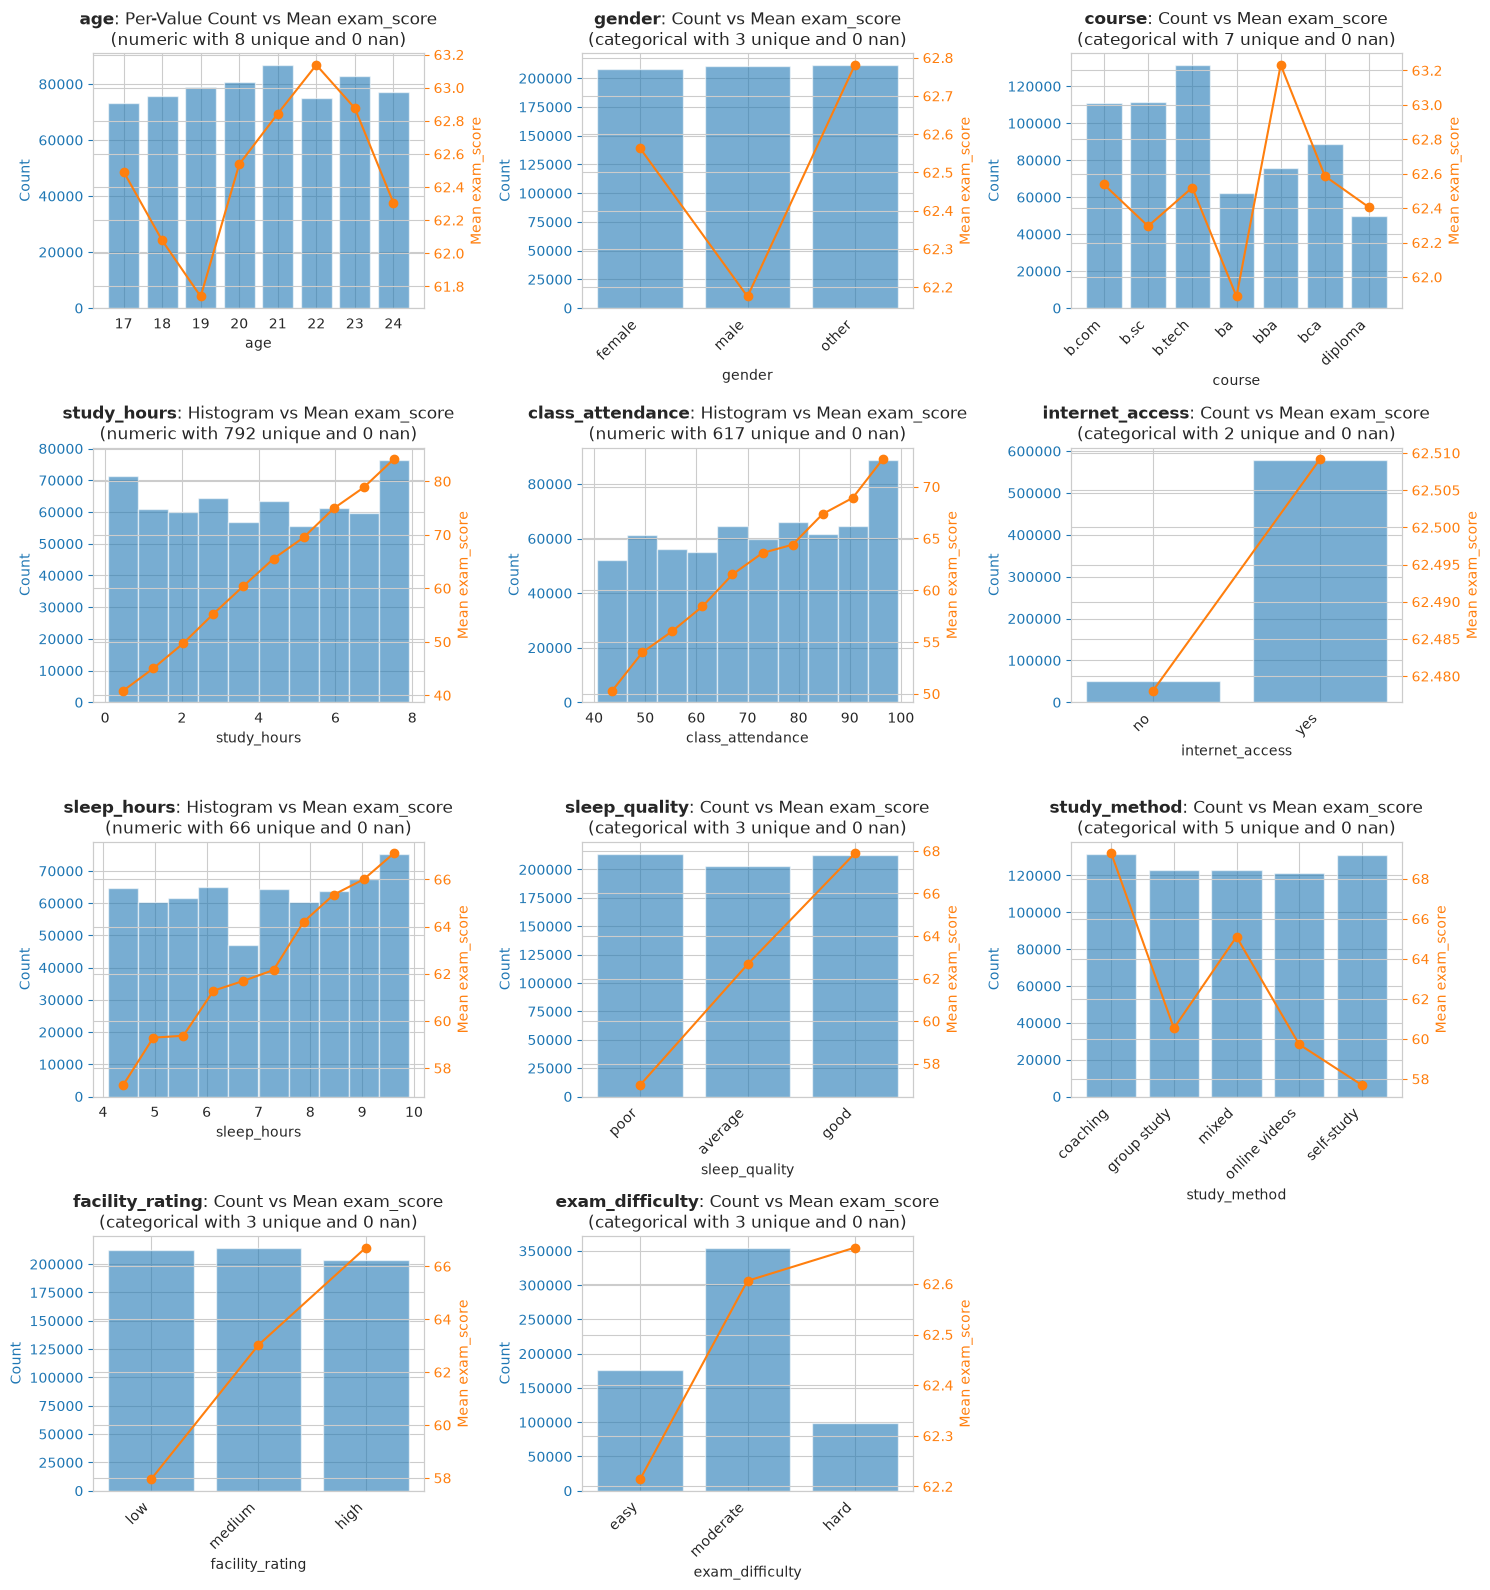

In [9]:
ordinal_order = {
    "sleep_quality": ["poor", "average", "good"],
    "facility_rating": ["low", "medium", "high"],
    "exam_difficulty": ["easy", "moderate", "hard"],
}

plot_features_dual_axis(
    train,
    cols=features,
    target_col="exam_score",
    n_bins=10,
    n_wide=3,
    int_as_cat_unique_max=20,
    cat_order=ordinal_order,
)

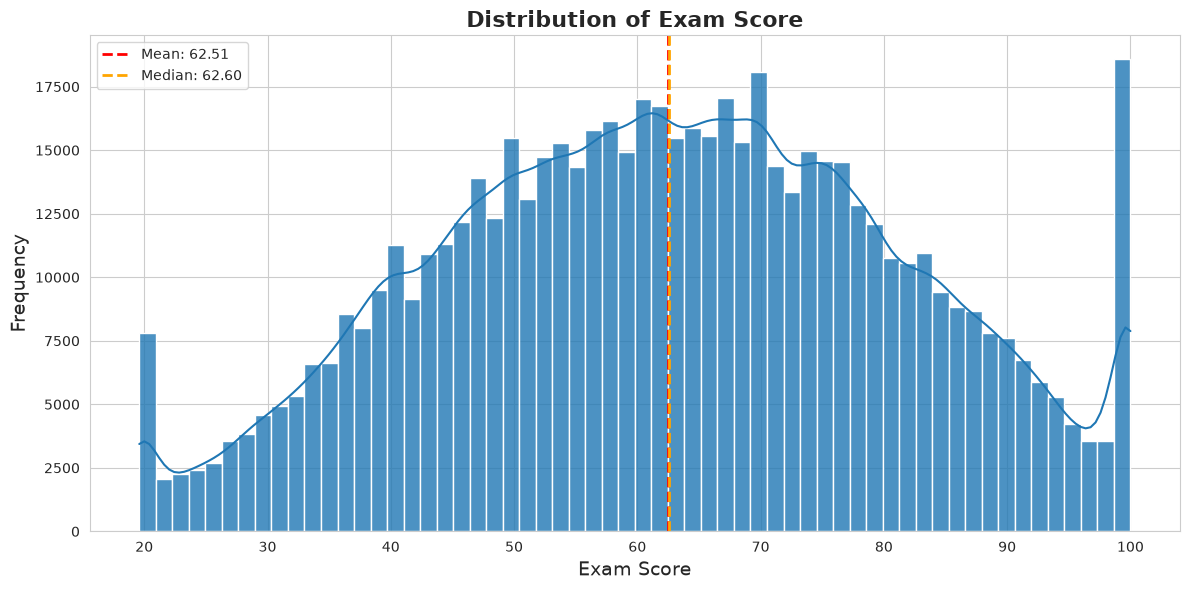

In [10]:
plt.figure(figsize=(12, 6))
sns.histplot(
    train["exam_score"],
    kde=True,
    bins=60,
    edgecolor="white",
    alpha=0.8,
)
plt.title("Distribution of Exam Score", fontsize=16, fontweight="bold")
plt.xlabel("Exam Score", fontsize=14)
plt.ylabel("Frequency", fontsize=14)
plt.axvline(
    train["exam_score"].mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f'Mean: {train["exam_score"].mean():.2f}',
)
plt.axvline(
    train["exam_score"].median(),
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f'Median: {train["exam_score"].median():.2f}',
)
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
train[numerical_features].describe()

,age,study_hours,class_attendance,sleep_hours
count,630000.000000,630000.000000,630000.000000,630000.000000
mean,20.545821,4.002337,71.987261,7.072758
std,2.260238,2.359880,17.430098,1.744811
min,17.000000,0.080000,40.600000,4.100000
25%,19.000000,1.970000,57.000000,5.600000
50%,21.000000,4.000000,72.600000,7.100000
75%,23.000000,6.050000,87.200000,8.600000
max,24.000000,7.910000,99.400000,9.900000


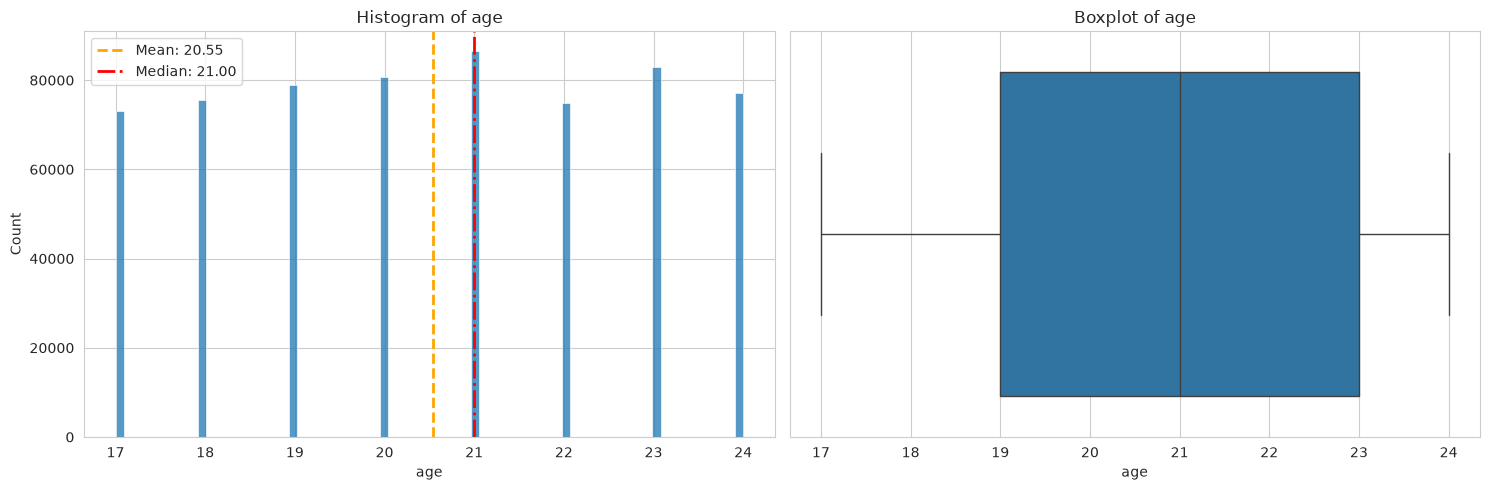

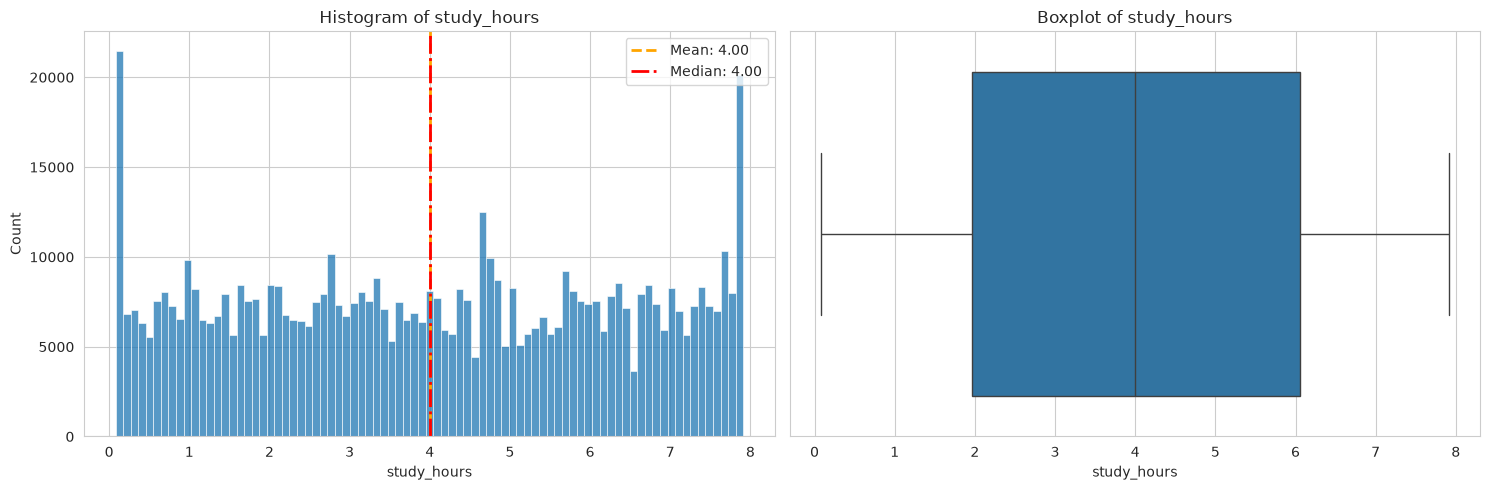

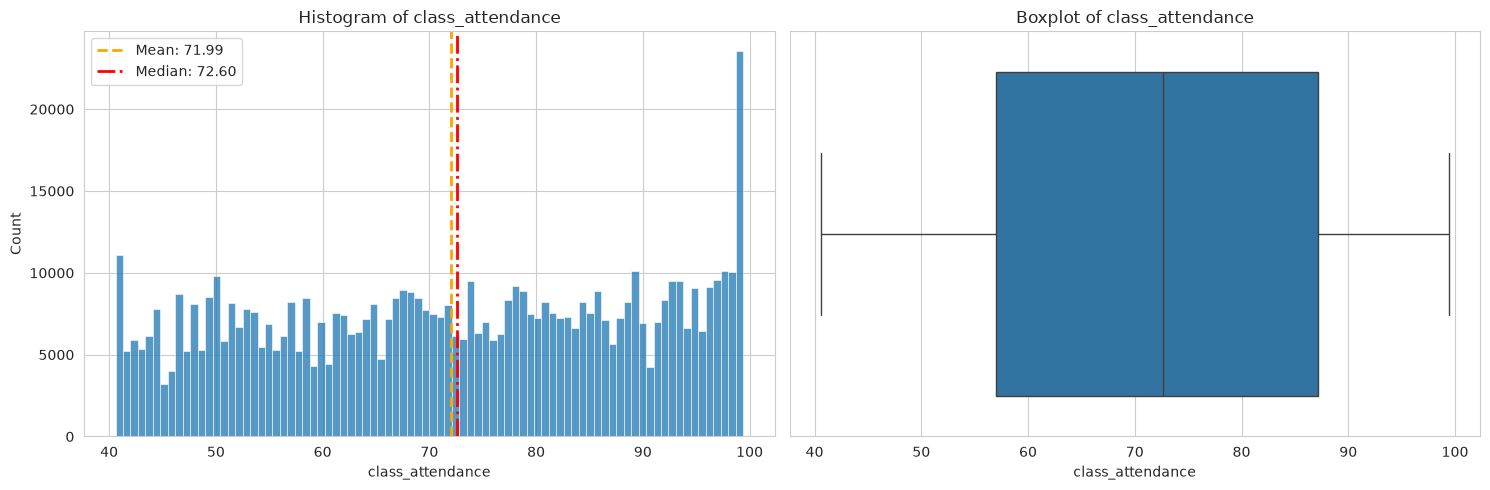

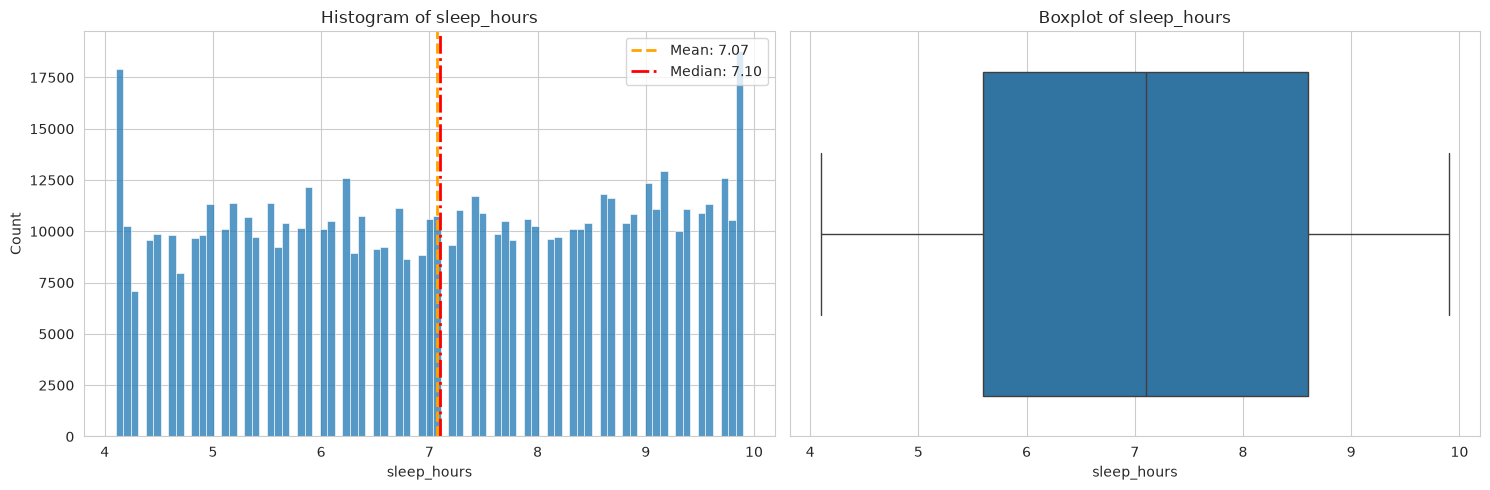

In [18]:
for column in numerical_features:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.histplot(data=train, x=column, ax=axes[0])
    mean_value = train[column].mean()
    median_value = train[column].median()
    axes[0].axvline(
        mean_value,
        color="orange",
        linestyle="--",
        linewidth=2,
        label=f"Mean: {mean_value:.2f}",
    )
    axes[0].axvline(
        median_value,
        color="red",
        linestyle="-.",
        linewidth=2,
        label=f"Median: {median_value:.2f}",
    )
    axes[0].set_title(f"Histogram of {column}")
    axes[0].legend()

    sns.boxplot(data=train, x=column, ax=axes[1])
    axes[1].set_title(f"Boxplot of {column}")

    plt.tight_layout()
plt.show()

In [19]:
train[categorical_features].describe()

,gender,course,internet_access,sleep_quality,study_method,facility_rating,exam_difficulty
count,630000,630000,630000,630000,630000,630000,630000
unique,3,7,2,3,5,3,3
top,other,b.tech,yes,poor,coaching,medium,moderate
freq,211097,131236,579423,213675,131697,214082,353982


In [20]:
import phik

correlations = {
    "Pearson": train.corr(numeric_only=True, method="pearson"),
    "Spearman": train.corr(numeric_only=True, method="spearman"),
    "Phik": train.phik_matrix(interval_cols=numerical_features + ["exam_score"]),
}

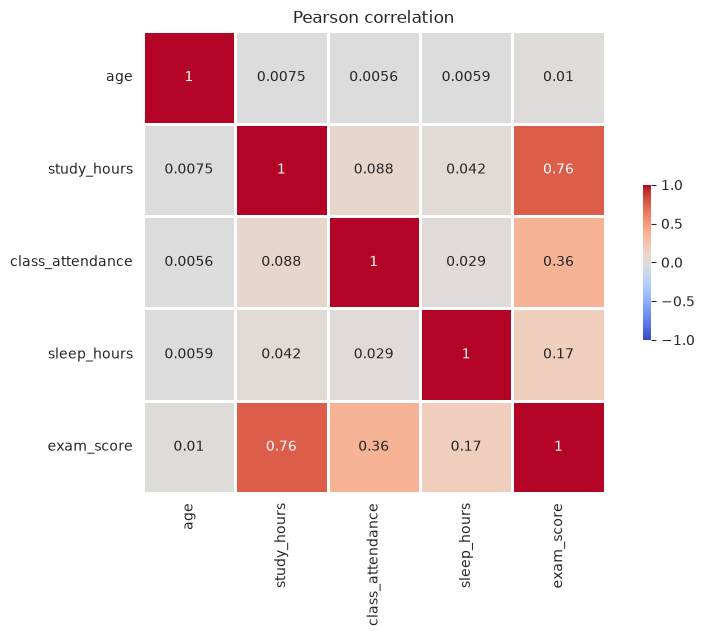

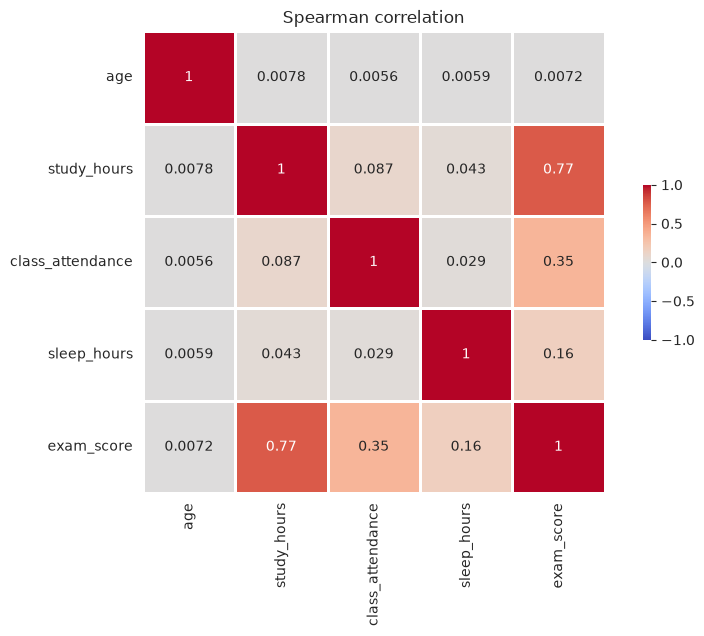

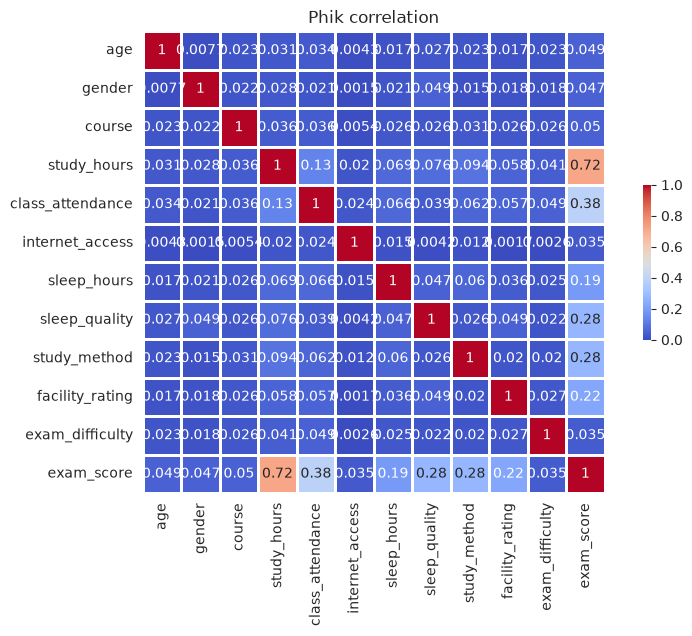

In [21]:
for name, matrix in correlations.items():
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        matrix,
        annot=True,
        square=True,
        cmap="coolwarm",
        vmax=1,
        vmin=0 if name == "Phik" else -1,
        cbar_kws={"fraction": 0.01},
        linewidth=2,
    )
    plt.title(f"{name} correlation")
    plt.show()

In [12]:
from sklearn.preprocessing import StandardScaler

n_estimators = 200
contamination = 0.01

scaler = StandardScaler()

data = train[numerical_features]
data_scaled = scaler.fit_transform(data)

model = core.ensemble.IsolationForest(
    n_estimators=n_estimators, contamination=contamination, random_state=42
)

anomaly_flags = model.fit_predict(data)
anomaly_score = model.decision_function(data)

In [13]:
anomaly_count = int(np.sum(anomaly_flags == -1))
print(f"Detected anomalies: {anomaly_count:,} / {len(train):,}")

Detected anomalies: 6,300 / 630,000


In [14]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
feature_2d = pca.fit_transform(data_scaled)

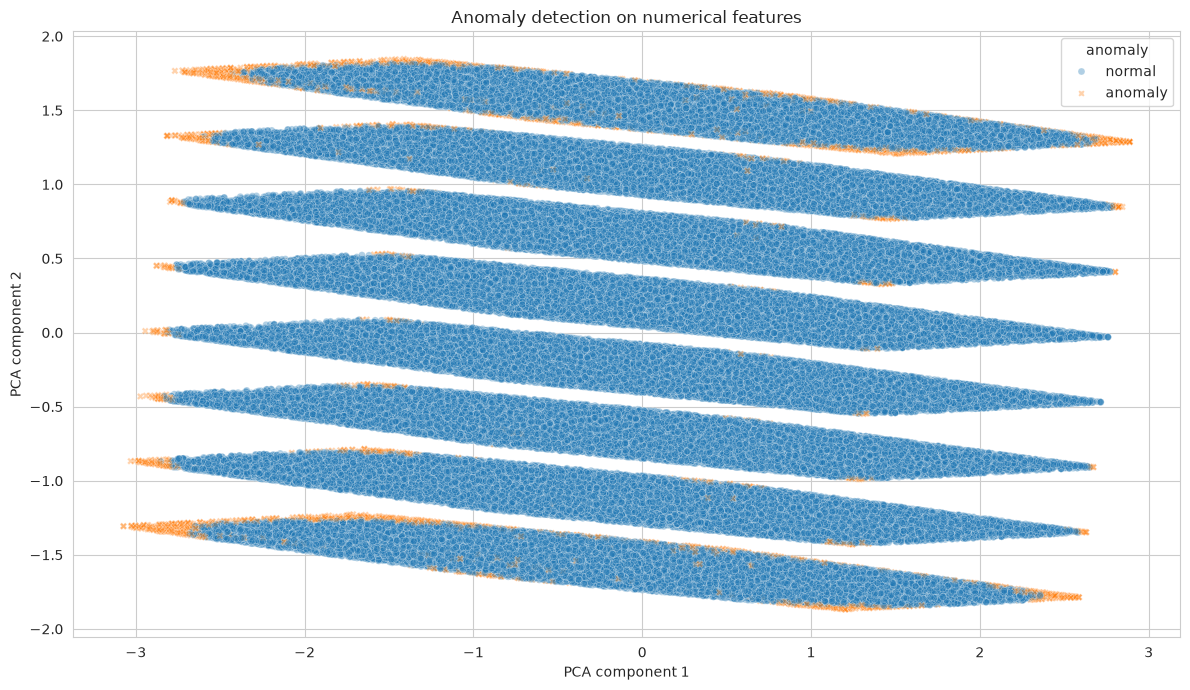

In [15]:
plot_df = pd.DataFrame(
    {
        "pc1": feature_2d[:, 0],
        "pc2": feature_2d[:, 1],
        "anomaly": np.where(anomaly_flags == -1, "anomaly", "normal"),
        "score": anomaly_score,
    }
)

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=plot_df,
    x="pc1",
    y="pc2",
    hue="anomaly",
    style="anomaly",
    alpha=0.35,
    s=25,
)
plt.title("Anomaly detection on numerical features")
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.tight_layout()
plt.show()

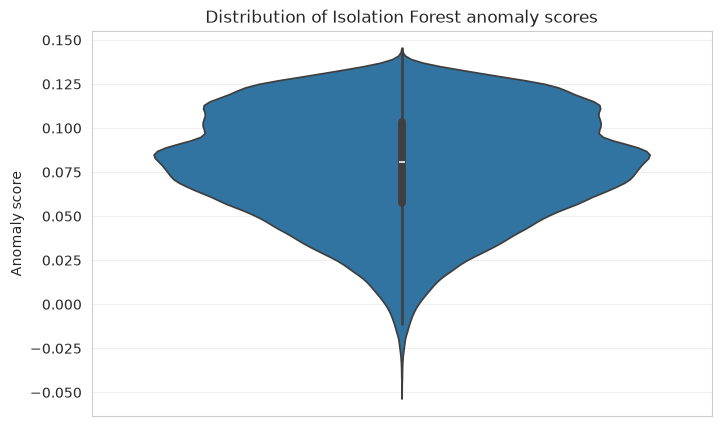

In [16]:
anomaly_indices = np.where(anomaly_flags == -1)[0]
anomaly_indices = anomaly_indices[np.argsort(anomaly_score[anomaly_indices])]

plt.figure(figsize=(8, 5))
sns.violinplot(
    y=anomaly_score,
    inner="box",
    cut=0,
)
plt.title("Distribution of Isolation Forest anomaly scores")
plt.ylabel("Anomaly score")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [17]:
train.iloc[anomaly_indices].head()

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
273118,24,male,b.sc,0.08,40.7,yes,4.1,average,online videos,high,hard,31.8
53171,17,other,b.sc,7.91,40.6,yes,9.9,poor,mixed,low,moderate,71.0
35218,17,female,b.tech,7.91,40.6,yes,9.9,average,group study,low,hard,88.8
250460,17,male,b.sc,7.90,40.6,yes,4.1,poor,self-study,medium,moderate,76.8
457600,17,male,b.sc,0.08,40.6,no,4.1,average,online videos,low,easy,35.4


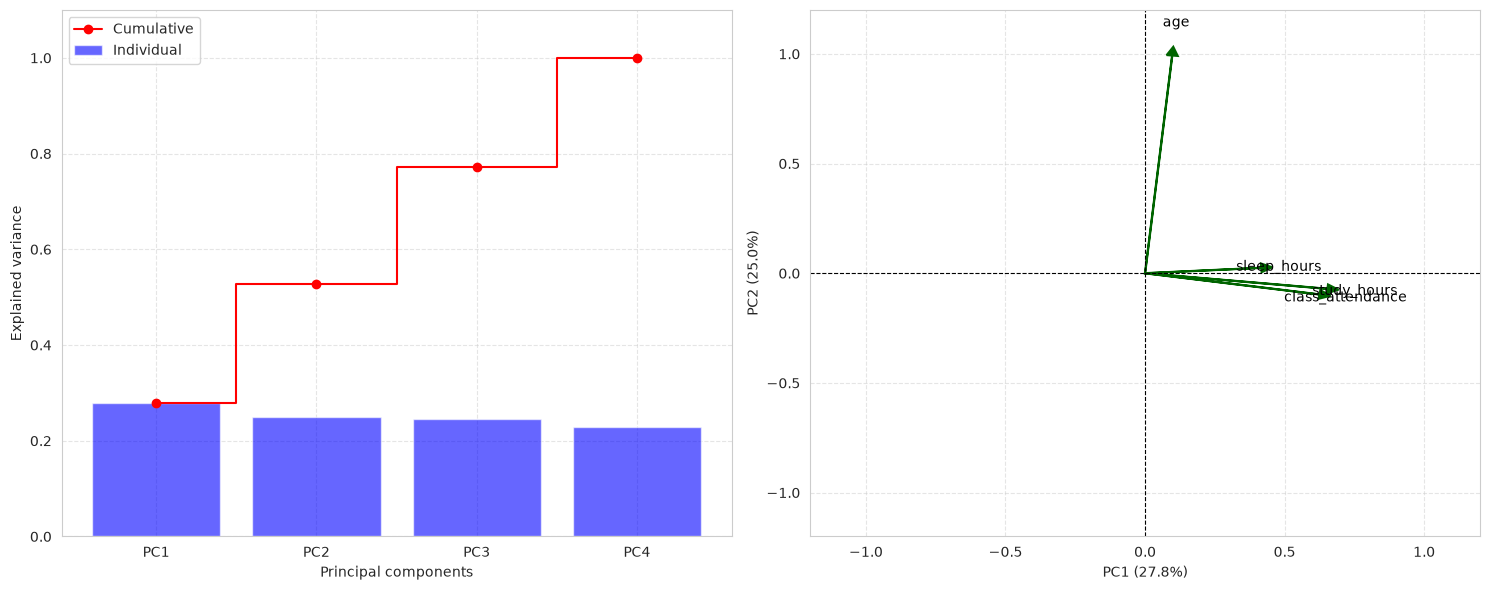

In [22]:
pca = PCA(random_state=42)
pca.fit(data_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(len(explained_variance))],
    index=numerical_features,
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

components = [f"PC{i+1}" for i in range(len(explained_variance))]
ax1.bar(components, explained_variance, alpha=0.6, color="b", label="Individual")
ax1.step(
    components,
    cumulative_variance,
    where="mid",
    color="r",
    marker="o",
    label="Cumulative",
)
ax1.set_xlabel("Principal components")
ax1.set_ylabel("Explained variance")
ax1.set_ylim(0, 1.1)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

for feature in loadings.index:
    ax2.arrow(
        0,
        0,
        loadings.loc[feature, "PC1"],
        loadings.loc[feature, "PC2"],
        head_width=0.04,
        head_length=0.04,
        color="darkgreen",
        linewidth=1.5,
    )

    ax2.text(
        loadings.loc[feature, "PC1"] * 1.15,
        loadings.loc[feature, "PC2"] * 1.15,
        feature,
        color="black",
        ha="center",
        va="center",
        fontsize=10,
    )

ax2.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax2.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax2.set_xlim(-1.2, 1.2)
ax2.set_ylim(-1.2, 1.2)
ax2.set_xlabel(f"PC1 ({explained_variance[0]:.1%})")
ax2.set_ylabel(f"PC2 ({explained_variance[1]:.1%})")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

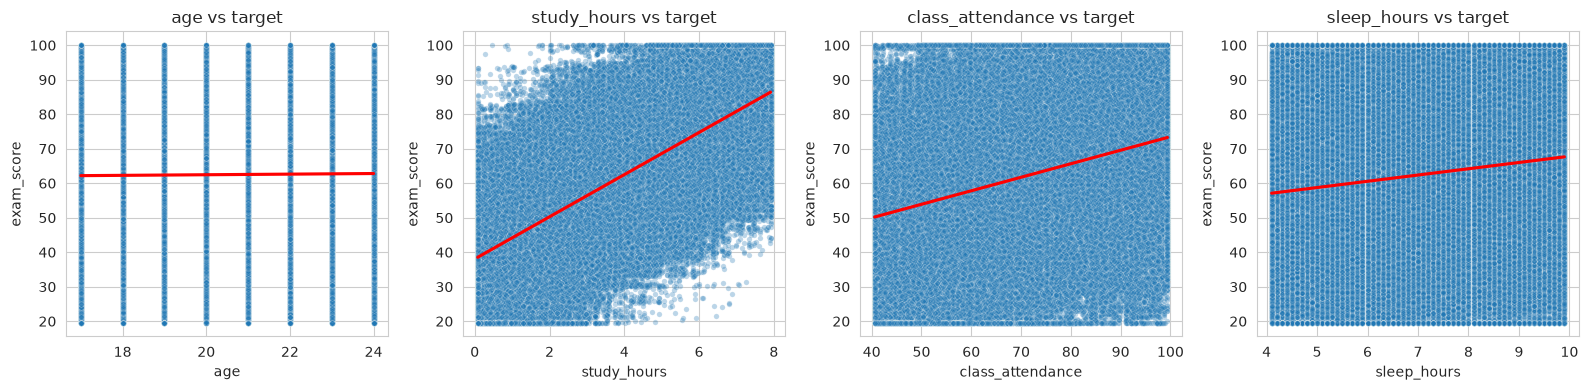

In [28]:
fig, axes = plt.subplots(
    1, len(numerical_features), figsize=(4 * len(numerical_features), 4)
)

for i, col in enumerate(numerical_features):
    sns.scatterplot(x=train[col], y=train["exam_score"], ax=axes[i], alpha=0.3, s=15)
    sns.regplot(
        x=train[col], y=train["exam_score"], ax=axes[i], scatter=False, color="red"
    )
    axes[i].set_title(f"{col} vs target")

plt.tight_layout()
plt.show()

In [12]:
def create_features(df: pd.DataFrame):
    df = df.copy()

    df["study_efficiency"] = df["study_hours"] * df["class_attendance"] / 100
    df["sleep_study_ratio"] = df["sleep_hours"] / (df["study_hours"] + 0.001)

    df["study_intensity"] = pd.cut(
        df["study_hours"],
        bins=[-np.inf, 3, 6, np.inf],
        labels=["low", "medium", "high"],
        include_lowest=True,
    )

    df["attendance_level"] = pd.cut(
        df["class_attendance"],
        bins=[-np.inf, 50, 75, 90, np.inf],
        labels=["poor", "average", "good", "excellent"],
        include_lowest=True,
    )

    return df

In [13]:
train_fe = create_features(train)

In [14]:
train_fe.head()

,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score,study_efficiency,sleep_study_ratio,study_intensity,attendance_level
0,21,female,b.sc,7.91,98.8,no,4.9,average,online videos,low,easy,78.3,7.81508,0.619391,high,excellent
1,18,other,diploma,4.95,94.8,yes,4.7,poor,self-study,medium,moderate,46.7,4.69260,0.949303,medium,excellent
2,20,female,b.sc,4.68,92.6,yes,5.8,poor,coaching,high,moderate,99.0,4.33368,1.239051,medium,excellent
3,19,male,b.sc,2.00,49.5,yes,8.3,average,group study,high,moderate,63.9,0.99000,4.147926,low,poor
4,23,male,bca,7.65,86.9,yes,9.6,good,self-study,high,easy,100.0,6.64785,1.254738,high,good


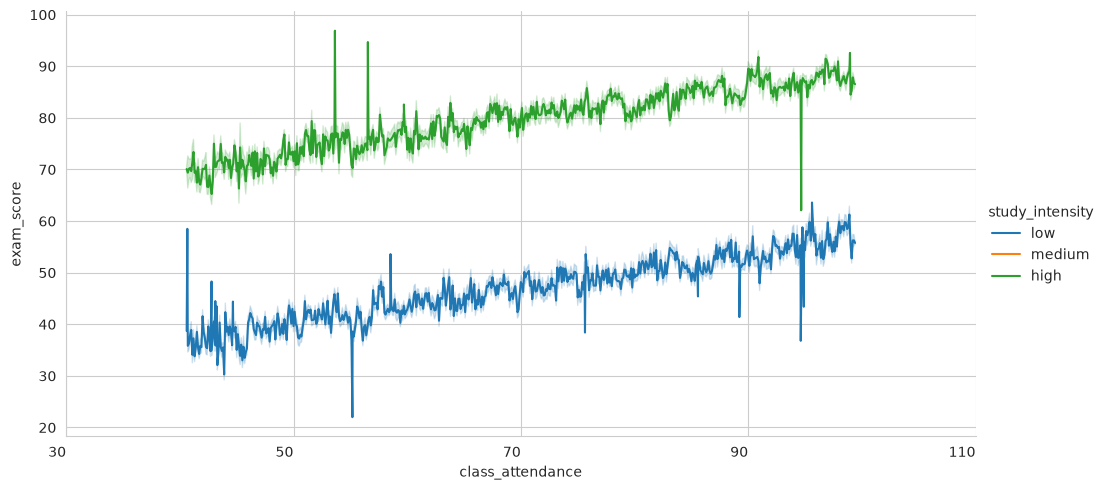

In [33]:
subset = train_fe[train_fe["study_intensity"].isin(["low", "high"])]

relplot = sns.relplot(
    data=subset,
    x="class_attendance",
    y="exam_score",
    hue="study_intensity",
    kind="line",
    aspect=2,
)
relplot.set_xticklabels(horizontalalignment="right", step=2)
plt.show()

In [15]:
y = train_fe["exam_score"]
X: pd.DataFrame = train_fe.drop("exam_score", axis=1)

In [16]:
X["internet_access"] = X["internet_access"].map({"no": 0, "yes": 1})
X["sleep_quality"] = X["sleep_quality"].map({"poor": 0, "average": 1, "good": 2})
X["facility_rating"] = X["facility_rating"].map({"low": 0, "medium": 1, "high": 2})
X["exam_difficulty"] = X["exam_difficulty"].map({"easy": 0, "moderate": 1, "hard": 2})
X["study_intensity"] = (
    X["study_intensity"].map({"low": 0, "medium": 1, "high": 2}).astype(int)
)
X["attendance_level"] = (
    X["attendance_level"]
    .map({"poor": 0, "average": 1, "good": 2, "excellent": 3})
    .astype(int)
)

course_ohe = pd.get_dummies(X["course"], prefix="course", dummy_na=True)
study_method_ohe = pd.get_dummies(
    X["study_method"], prefix="study_method", dummy_na=True
)
gender_ohe = pd.get_dummies(
    X["gender"],
    prefix="gender",
    dummy_na=True,
)

X.drop("course", axis=1, inplace=True)
X.drop("study_method", axis=1, inplace=True)
X.drop("gender", axis=1, inplace=True)

X = pd.concat([X, course_ohe, study_method_ohe, gender_ohe], axis=1)

In [17]:
X.head()

,age,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,facility_rating,exam_difficulty,study_efficiency,sleep_study_ratio,...,study_method_coaching,study_method_group study,study_method_mixed,study_method_online videos,study_method_self-study,study_method_nan,gender_female,gender_male,gender_other,gender_nan
0,21,7.91,98.8,0,4.9,1,0,0,7.81508,0.619391,...,False,False,False,True,False,False,True,False,False,False
1,18,4.95,94.8,1,4.7,0,1,1,4.69260,0.949303,...,False,False,False,False,True,False,False,False,True,False
2,20,4.68,92.6,1,5.8,0,2,1,4.33368,1.239051,...,True,False,False,False,False,False,True,False,False,False
3,19,2.00,49.5,1,8.3,1,2,1,0.99000,4.147926,...,False,True,False,False,False,False,False,True,False,False
4,23,7.65,86.9,1,9.6,2,2,0,6.64785,1.254738,...,False,False,False,False,True,False,False,True,False,False


In [18]:
X.columns.tolist()

['age',
 'study_hours',
 'class_attendance',
 'internet_access',
 'sleep_hours',
 'sleep_quality',
 'facility_rating',
 'exam_difficulty',
 'study_efficiency',
 'sleep_study_ratio',
 'study_intensity',
 'attendance_level',
 'course_b.com',
 'course_b.sc',
 'course_b.tech',
 'course_ba',
 'course_bba',
 'course_bca',
 'course_diploma',
 'course_nan',
 'study_method_coaching',
 'study_method_group study',
 'study_method_mixed',
 'study_method_online videos',
 'study_method_self-study',
 'study_method_nan',
 'gender_female',
 'gender_male',
 'gender_other',
 'gender_nan']

In [21]:
new_numerical_features = numerical_features + ["study_efficiency", "sleep_study_ratio"]

discrete_mask = ~X.columns.isin(new_numerical_features)

In [ ]:
scaler: StandardScaler = StandardScaler().set_output(transform="pandas")

X_scaled: pd.DataFrame = X.copy()
X_scaled[new_numerical_features] = scaler.fit_transform(X[new_numerical_features])

In [41]:
X_scaled.head()

,age,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,facility_rating,exam_difficulty,study_efficiency,sleep_study_ratio,...,study_method_coaching,study_method_group study,study_method_mixed,study_method_online videos,study_method_self-study,study_method_nan,gender_female,gender_male,gender_other,gender_nan
0,0.200943,1.655875,1.538302,0,-1.245269,1,0,0,2.535425,-0.357955,...,False,False,False,True,False,False,True,False,False,False
1,-1.126352,0.401573,1.308814,1,-1.359895,0,1,1,0.919045,-0.334831,...,False,False,False,False,True,False,False,False,True,False
2,-0.241488,0.287160,1.182595,1,-0.729454,0,2,1,0.733247,-0.314521,...,True,False,False,False,False,False,True,False,False,False
3,-0.683920,-0.848492,-1.290141,1,0.703367,1,2,1,-0.997639,-0.110631,...,False,True,False,False,False,False,False,True,False,False
4,1.085807,1.545699,0.855575,1,1.448434,2,2,0,1.931198,-0.313422,...,False,False,False,False,True,False,False,True,False,False


In [22]:
from sklearn.feature_selection import mutual_info_regression

rng = np.random.default_rng(42)

sample_size = min(100_000, len(X))
idx = rng.choice(
    len(X),
    size=sample_size,
    replace=False,
)

mi = mutual_info_regression(
    X.iloc[idx],
    y.iloc[idx],
    discrete_features=discrete_mask,
    n_neighbors=5,
    random_state=42,
    n_jobs=-1,
)

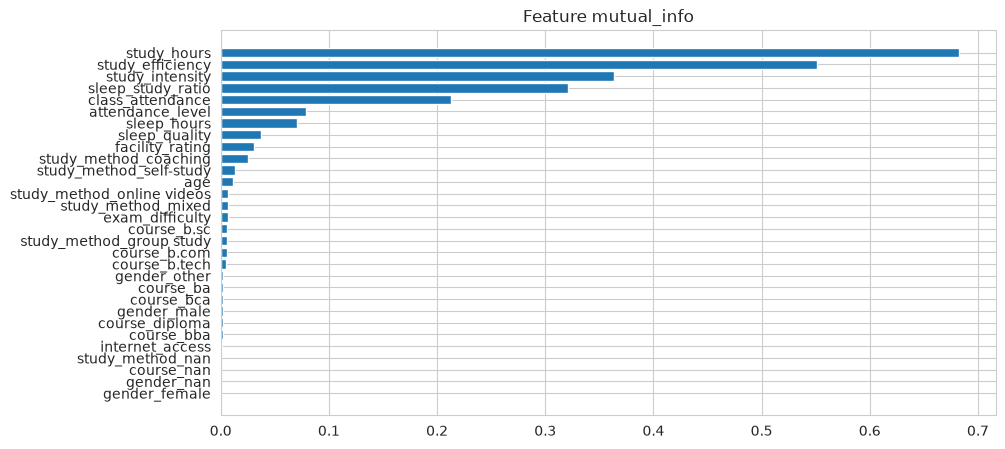

In [24]:
df_mi = pd.DataFrame({"mi_feature": X.columns, "mutual_information": mi})
df_mi = df_mi.sort_values(by="mutual_information", ascending=False).reset_index(
    drop=True
)

fig = plt.figure(figsize=(10, 5))
sorted_idx = np.argsort(df_mi["mutual_information"])
plt.barh(
    range(df_mi.shape[0]), df_mi["mutual_information"].iloc[sorted_idx], align="center"
)
plt.yticks(range(df_mi.shape[0]), df_mi["mi_feature"].iloc[sorted_idx])
plt.title("Feature mutual_info")
plt.show()

In [31]:
df_mi

,mi_feature,mutual_information
0,study_hours,0.682305
1,study_efficiency,0.550784
2,study_intensity,0.363815
3,sleep_study_ratio,0.320894
4,class_attendance,0.212770
5,attendance_level,0.078774
6,sleep_hours,0.070075
7,sleep_quality,0.037250
8,facility_rating,0.031183
9,study_method_coaching,0.025466


In [27]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    random_state=42,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="reg:squarederror",
    n_jobs=-1,
    eval_metric="rmse",
    tree_method="hist",
    device=device,
)

In [28]:
# feature importance estimation
xgb_model.fit(X, y, eval_set=[(X, y)], verbose=100)

[0]	validation_0-rmse:18.24222
[100]	validation_0-rmse:8.81882
[200]	validation_0-rmse:8.75812
[300]	validation_0-rmse:8.71726
[400]	validation_0-rmse:8.68674
[500]	validation_0-rmse:8.66022
[600]	validation_0-rmse:8.63615
[700]	validation_0-rmse:8.61573
[800]	validation_0-rmse:8.59607
[900]	validation_0-rmse:8.57785
[999]	validation_0-rmse:8.56034


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


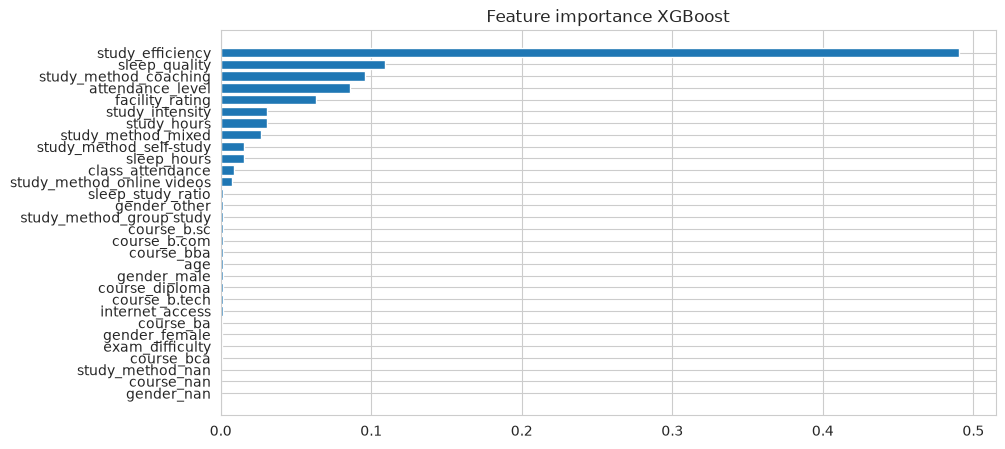

In [32]:
df_fi = (
    pd.DataFrame(
        {"fi_feature": X.columns, "importance": xgb_model.feature_importances_}
    )
    .sort_values(by="importance", ascending=False)
    .reset_index(drop=True)
)

fig = plt.figure(figsize=(10, 5))
sorted_idx = np.argsort(df_fi["importance"])
plt.barh(range(df_fi.shape[0]), df_fi["importance"].iloc[sorted_idx], align="center")
plt.yticks(range(df_mi.shape[0]), df_fi["fi_feature"].iloc[sorted_idx])
plt.title("Feature importance XGBoost")
plt.show()

In [33]:
df_fi

,fi_feature,importance
0,study_efficiency,0.490329
1,sleep_quality,0.108917
2,study_method_coaching,0.095792
3,attendance_level,0.085656
4,facility_rating,0.063387
5,study_intensity,0.031061
6,study_hours,0.030636
7,study_method_mixed,0.026905
8,study_method_self-study,0.015760
9,sleep_hours,0.015248


In [ ]:
from boruta import BorutaPy

model = core.ensemble.RandomForestRegressor(n_estimators=500, random_state=42)

feat_selector = BorutaPy(model, n_estimators=100, verbose=1, random_state=42)

feat_selector.fit(X.iloc[idx].values, y.iloc[idx].values)

Iteration: 1 / 100
Iteration: 2 / 100
Iteration: 3 / 100
Iteration: 4 / 100
Iteration: 5 / 100
Iteration: 6 / 100
Iteration: 7 / 100
Iteration: 8 / 100


BorutaPy finished running.

Iteration: 	9 / 100
Confirmed: 	6
Tentative: 	0
Rejected: 	24


,estimator,RandomForestR...x7D80555C9440)
,n_estimators,100
,random_state,RandomState(M...0x7D80555C9440
,verbose,1
,perc,100
,alpha,0.05
,two_step,True
,max_iter,100
,early_stopping,False
,n_iter_no_change,20
Name,Type,Value


In [36]:
feature_ranks = list(zip(X.columns, feat_selector.ranking_, feat_selector.support_))

df_rank = pd.DataFrame(feature_ranks, columns=["feature", "rank", "boruta_keep"])
df_rank.sort_values(by="rank", ascending=True).reset_index(drop=True)

,feature,rank,boruta_keep
0,class_attendance,1,True
1,facility_rating,1,True
2,sleep_quality,1,True
3,sleep_hours,1,True
4,study_efficiency,1,True
5,study_method_coaching,1,True
6,study_hours,2,False
7,sleep_study_ratio,3,False
8,age,4,False
9,study_method_mixed,5,False


In [ ]:
preprocessed: pd.DataFrame = X.copy()
preprocessed["target"] = y

preprocessed.to_parquet("preprocessed.parquet")